In [2]:
!pip install numpy matplotlib pandas tensorflow

In [26]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

In [3]:
import sys; print(sys.executable)

/home/vedh/miniconda3/envs/mlcv/bin/python


In [4]:
import tensorflow as tf
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
# !python3 -c "import tensorflow as tf; print(tf.__version__)"
# !pip install nvidia-cuda-runtime-cu11 nvidia-cublas-cu11 nvidia-cufft-cu11 nvidia-curand-cu11 nvidia-cusolver-cu11 nvidia-cusparse-cu11 nvidia-cudnn-cu11
# !export LD_LIBRARY_PATH=$VIRTUAL_ENV/lib/python3.*/site-packages/nvidia/*/lib:$LD_LIBRARY_PATH
# !nvidia-smi
# !python3 -c "import tensorflow as tf; print(tf.__version__)"


Num GPUs Available:  1


In [5]:
# import numpy as np
# import tensorflow as tf
# import time

# n = 8000
# A_np = np.random.rand(n, n)
# B_np = np.random.rand(n, n)

# A_tf = tf.convert_to_tensor(A_np)
# B_tf = tf.convert_to_tensor(B_np)
# start_time = time.time()
# C_tf = np.dot(A_tf, B_tf)
# end_time = time.time()
# print("Time taken for matrix multiplication using numpy: {:.6f} seconds".format(end_time - start_time))


# start_time = time.time()
# with tf.device('/GPU:0'):
#     C_tf = tf.matmul(A_tf, B_tf)
# end_time = time.time()
# print("Time taken for matrix multiplication using TensorFlow: {:.6f} seconds".format(end_time - start_time))

In [6]:
!nvidia-smi

Mon Oct 12 23:18:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...    Off |   00000000:01:00.0  On |                  N/A |
| N/A   70C    P8             11W /   20W |      66MiB /   4096MiB |      1%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# DATA PREPERATION

In [7]:
import tensorflow as tf

IMG_HEIGHT = 32
IMG_WIDTH = 32
IMG_CHANNELS = 3

IMG_DIR = '/home/vedh/workspaces/mlcv_ws/src/datasets/cifar-10/train'
CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

In [8]:
def read_and_decode(filename):
    ## READ THE RAW FILE
    raw_bytes = tf.io.read_file(filename)
    ## DECODE THE IMAGE
    img = tf.image.decode_png(raw_bytes, channels=IMG_CHANNELS)
    ## CONVERT PIXEL VALUES TO FLOAT32 in [0, 1]
    img = tf.image.convert_image_dtype(img, tf.float32)
    return img

def parse_csvline(csv_line):
    id_str, label_string = tf.io.decode_csv(csv_line, record_defaults =["", ""])
    filename = IMG_DIR + "/" + id_str + ".png"
    img = read_and_decode(filename)
    label = tf.argmax(tf.cast(tf.math.equal(CLASS_NAMES, label_string), tf.int32))
    return img, label


In [15]:
train_dataset = (tf.data.TextLineDataset("/home/vedh/workspaces/mlcv_ws/src/datasets/cifar-10/trainLabels.csv")
                 .skip(1)
                 .shuffle(50000)
                 .map(parse_csvline, num_parallel_calls=tf.data.AUTOTUNE))


test_dataset = (train_dataset.skip(40000)
                .batch(64)
                .prefetch(tf.data.AUTOTUNE)
                )

train_dataset = (
    train_dataset
    .take(40000)
    .batch(64)
    .prefetch(tf.data.AUTOTUNE)
)
print("Train dataset size:", sum(1 for _ in train_dataset))
print("Test dataset size:", sum(1 for _ in test_dataset))


Train dataset size: 625
Test dataset size: 157


In [16]:
for image_batch, label_batch in train_dataset.take(1):
    print("Image batch shape:", image_batch.shape)
    print("Label batch shape:", label_batch.shape)
    print("Labels:", label_batch.numpy())

Image batch shape: (64, 32, 32, 3)
Label batch shape: (64,)
Labels: [9 9 1 5 2 0 4 5 9 0 7 6 4 1 9 8 4 7 9 2 5 7 7 7 7 5 5 0 8 3 9 0 4 9 6 2 0
 8 0 0 3 6 5 2 5 7 9 2 2 6 2 8 2 4 9 2 5 1 4 0 2 1 4 4]


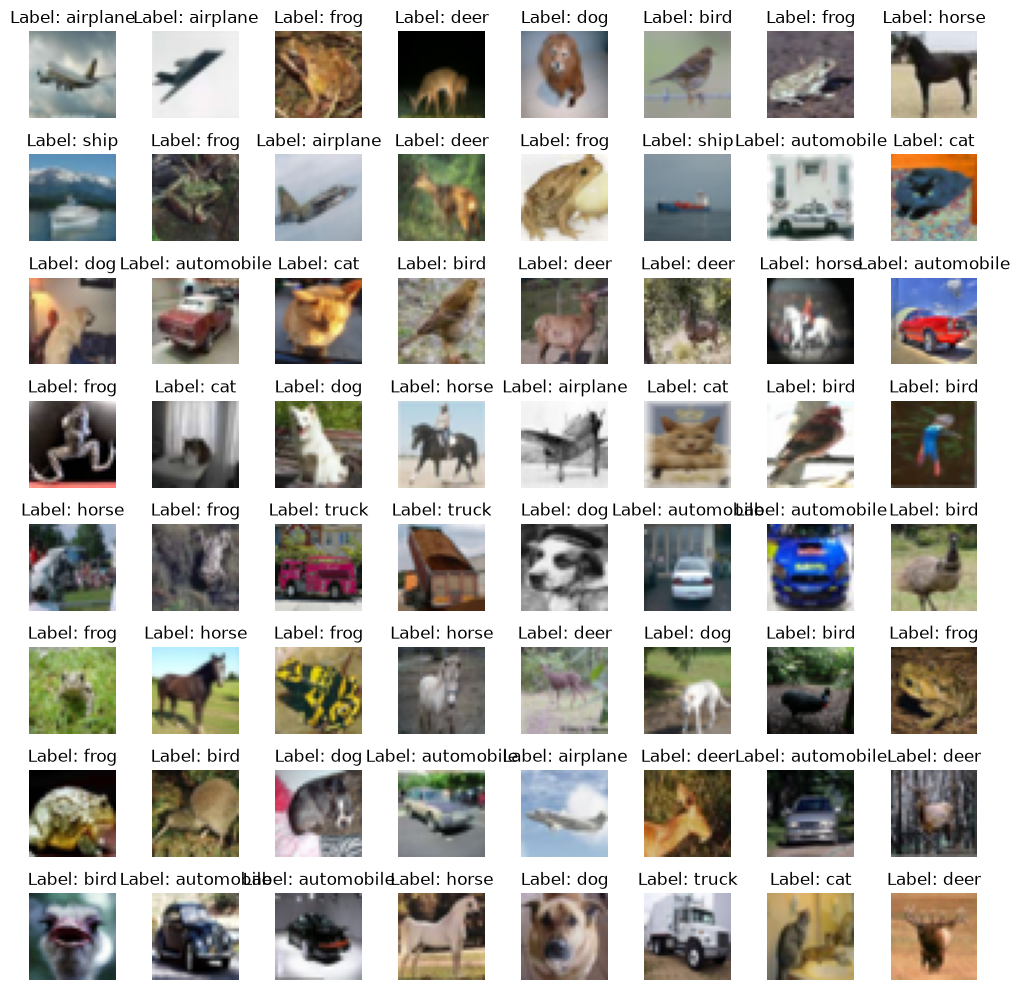

In [18]:
import matplotlib.pyplot as plt

for image_batch, label_batch in train_dataset.take(1):
    fig, axes = plt.subplots(8, 8, figsize=(10, 10))
    for i in range(64):
        ax = axes[i // 8, i % 8]
        ax.imshow(image_batch[i])
        ax.set_title(f"Label: {CLASS_NAMES[label_batch[i]]}")
        ax.axis('off') # Hide axes

    plt.tight_layout()
    plt.show()

## MODEL ARCHITECTURE DESIGN

In [19]:
from tensorflow import keras
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)),
    keras.layers.Dense(len(CLASS_NAMES), activation="softmax")
])

model.compile(optimizer="adam",
            loss= keras.losses.SparseCategoricalCrossentropy(from_logits=False),
            metrics=["accuracy"])

/home/vedh/miniconda3/envs/mlcv/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [27]:
EPOCHS = 100
history = model.fit(train_dataset,validation_data=test_dataset, epochs=EPOCHS, verbose=2)

Epoch 1/100


I0000 00:00:1791828657.335321   23798 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791828657.335361   23798 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187


625/625 - 3s - 5ms/step - accuracy: 0.4286 - loss: 1.6702 - val_accuracy: 0.4407 - val_loss: 1.6462
Epoch 2/100


I0000 00:00:1791828659.086610   23868 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791828659.086666   23868 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187
I0000 00:00:1791828660.858297   23798 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791828660.858348   23798 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187


625/625 - 3s - 5ms/step - accuracy: 0.4290 - loss: 1.6731 - val_accuracy: 0.4540 - val_loss: 1.6080
Epoch 3/100


...

I0000 00:00:1791829130.303195   23868 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791829130.303313   23868 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187
I0000 00:00:1791829133.397019   23798 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791829133.397100   23798 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187


625/625 - 6s - 9ms/step - accuracy: 0.4342 - loss: 1.6564 - val_accuracy: 0.4348 - val_loss: 1.6629
Epoch 100/100


I0000 00:00:1791829135.946289   23868 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791829135.946352   23868 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187
I0000 00:00:1791829139.373727   23798 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791829139.373796   23798 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187


625/625 - 5s - 8ms/step - accuracy: 0.4354 - loss: 1.6505 - val_accuracy: 0.4273 - val_loss: 1.6631


I0000 00:00:1791829141.215175   23868 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791829141.215245   23868 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187


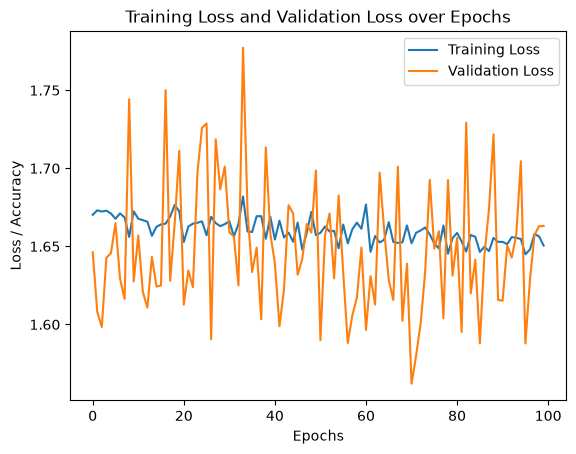

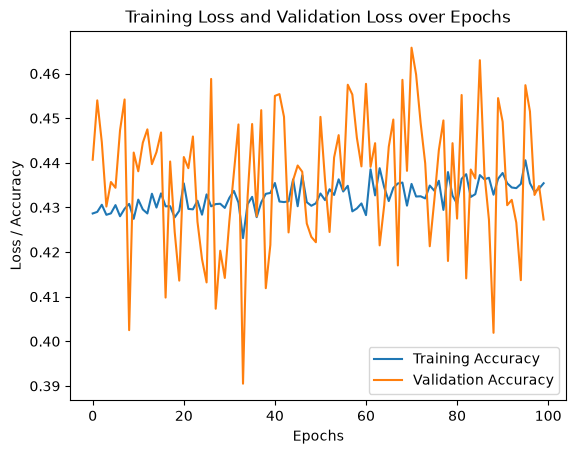

In [28]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel("Loss / Accuracy")
plt.title("Training Loss and Validation Loss over Epochs")
plt.legend()
plt.show()

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel("Loss / Accuracy")
plt.title("Training Loss and Validation Loss over Epochs")
plt.legend()
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


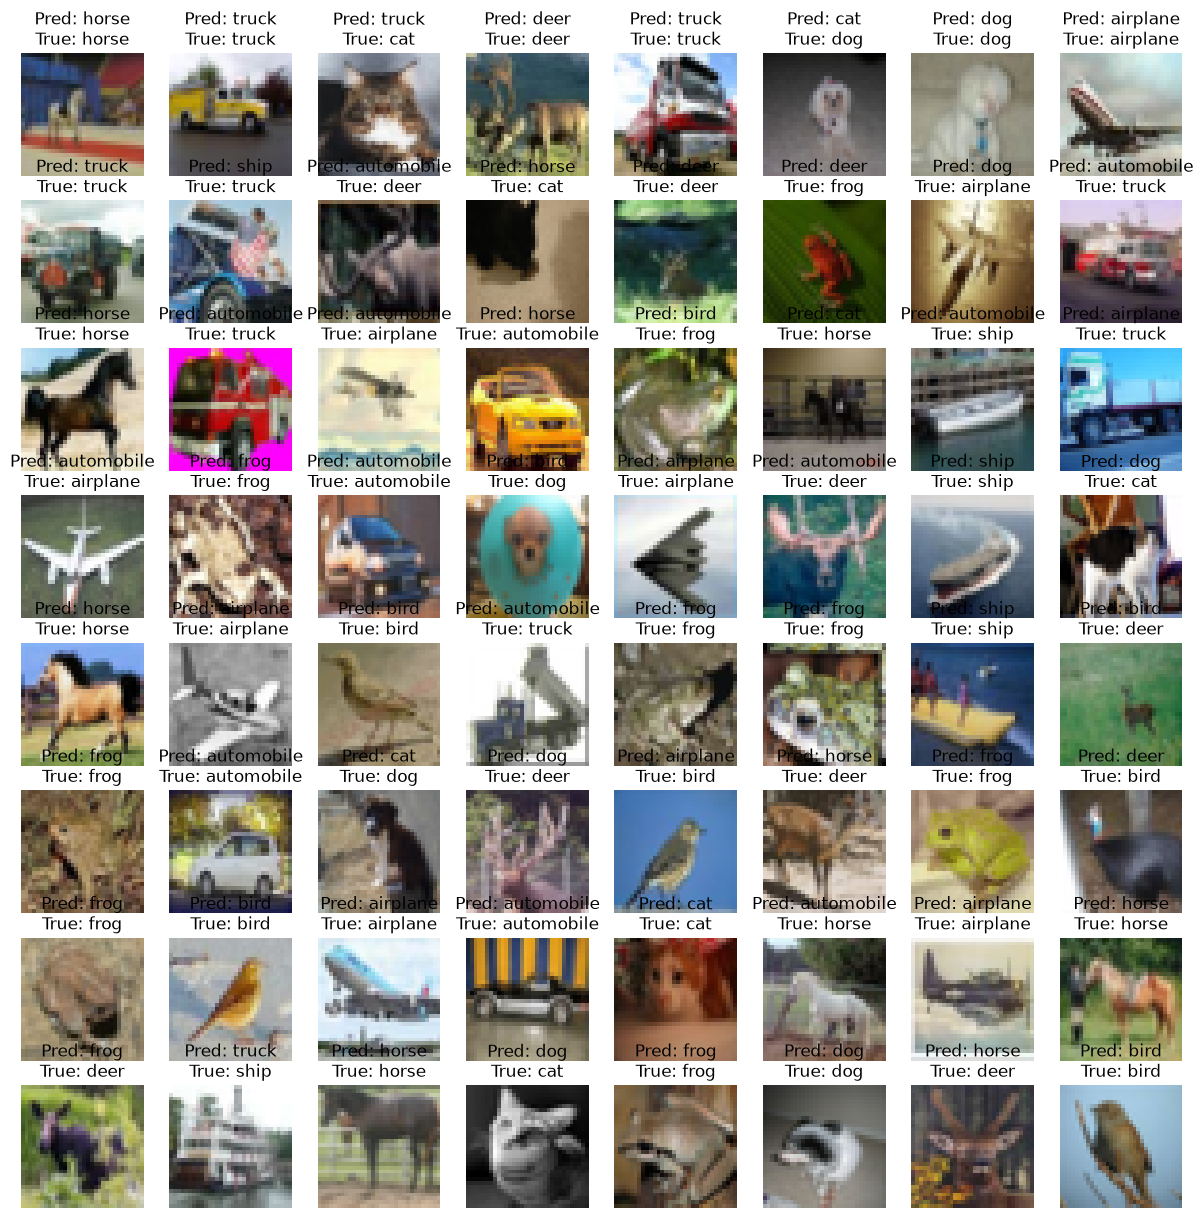

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import math 

for images, labels in test_dataset.take(1):
    predictions = model.predict(images)
    predicted_indices = np.argmax(predictions, axis=1)
    fig, axes = plt.subplots(8, 8, figsize=(15, 15))
    for i in range(64):
        ax = axes[i // 8, i % 8]
        ax.imshow(images[i])
        ax.set_title(f"Pred: {CLASS_NAMES[predicted_indices[i]]}\nTrue: {CLASS_NAMES[labels[i]]}")
        ax.axis('off') # Hide axes

## MODEL 2 ( More than simple linear flattening layer)

In [35]:
from tensorflow import keras
model2 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)),
    tf.keras.layers.Dense(128, activation="relu"),
    # tf.keras.layers.Dense(48, activation="relu"), 
    tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax")
])

## TOTAL WEIGHTS = (32*32*3 + 1)* 128 + (128+1)*48 + (48+1)*10 = 400026

model2.compile(
            optimizer="adam",
            loss= keras.losses.SparseCategoricalCrossentropy(from_logits=False),
            metrics=["accuracy"]
            )

In [38]:
EPOCHS = 25
history2 = model2.fit(train_dataset,validation_data=test_dataset, epochs=EPOCHS, verbose=2)

Epoch 1/25


I0000 00:00:1791830987.657084   39338 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791830987.657125   39338 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187


625/625 - 3s - 5ms/step - accuracy: 0.4379 - loss: 1.5789 - val_accuracy: 0.4398 - val_loss: 1.5586
Epoch 2/25


I0000 00:00:1791830988.765953   39425 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791830988.765995   39425 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187
I0000 00:00:1791830990.714481   39338 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791830990.714513   39338 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187


625/625 - 3s - 5ms/step - accuracy: 0.4422 - loss: 1.5660 - val_accuracy: 0.4515 - val_loss: 1.5236
Epoch 3/25


...

I0000 00:00:1791831076.400625   39425 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791831076.400730   39425 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187
I0000 00:00:1791831079.166685   39338 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791831079.166746   39338 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187


625/625 - 5s - 8ms/step - accuracy: 0.4788 - loss: 1.4620 - val_accuracy: 0.4869 - val_loss: 1.4550
Epoch 25/25


I0000 00:00:1791831081.203190   39425 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791831081.203262   39425 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187
I0000 00:00:1791831083.607157   39338 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791831083.607199   39338 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187


625/625 - 4s - 7ms/step - accuracy: 0.4772 - loss: 1.4630 - val_accuracy: 0.4738 - val_loss: 1.4766


I0000 00:00:1791831085.278431   39425 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 5713765217024461177
I0000 00:00:1791831085.278497   39425 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 7365945695685233187


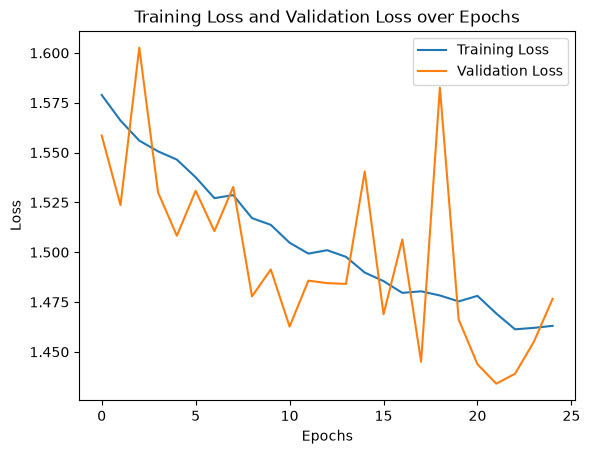

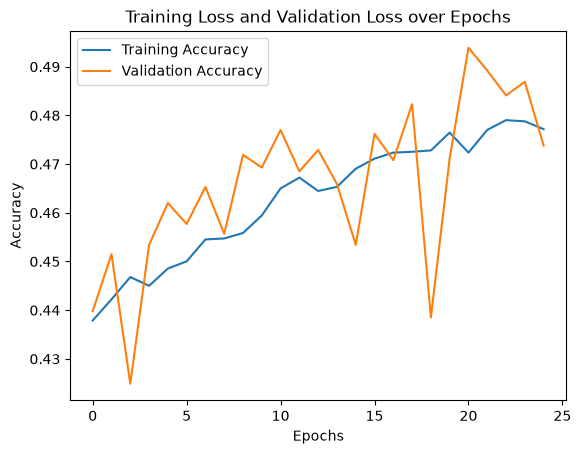

In [40]:
import matplotlib.pyplot as plt
plt.plot(history2.history['loss'], label='Training Loss')
plt.plot(history2.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel("Loss")
plt.title("Training Loss and Validation Loss over Epochs")
plt.legend()
plt.show()

plt.plot(history2.history['accuracy'], label='Training Accuracy')
plt.plot(history2.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel("Accuracy")
plt.title("Training Loss and Validation Loss over Epochs")
plt.legend()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math 

for images, labels in test_dataset.take(1):
    predictions = model2.predict(images)
    predicted_indices = np.argmax(predictions, axis=1)
    fig, axes = plt.subplots(8, 8, figsize=(15, 15))
    for i in range(64):
        ax = axes[i // 8, i % 8]
        ax.imshow(images[i])
        ax.set_title(f"Pred: {CLASS_NAMES[predicted_indices[i]]}\nTrue: {CLASS_NAMES[labels[i]]}")
        ax.axis('off') # Hide axes